In [4]:
import numpy as np
import skimage.io
import skimage.color
import skimage.filters
import skimage.transform
import matplotlib.pyplot as plt
import os
import shutil
import pandas as pd
import tensorflow as tf
from keras import layers
import keras
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import time
from joblib import Parallel, delayed
import joblib

# hp = keras_tuner.HyperParameters()

print(tf.__version__)
print(tf.config.list_physical_devices())

2.10.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
def test_model(model, dataset):
    filtered_data = []
    TP = 0
    FP = 0
    TN = 0
    FN = 0
    for i, (images, label) in enumerate(dataset, 0):
        output = model(images)
        prediction = output.numpy()
        for i in range(len(prediction)):
            if prediction[i][0] > 0.4:
                if label[i]== 1:
                    TP += 1
                else: FP += 1
                filtered_data.append(images[i])
                # print(prediction[i], label[i])
            else:
                if label[i]== 1:
                    FN += 1
                else: TN += 1
    return filtered_data, TP, FP, TN, FN

In [3]:
train_ds, valid_ds = keras.utils.image_dataset_from_directory(
    directory='./data2/images_512_train/',
    labels='inferred',
    label_mode='binary',
    batch_size=10,
    image_size=(512,512),
    validation_split=0.2,
    subset='both',
    seed=42
)
test_ds = keras.utils.image_dataset_from_directory(
    directory='./data2/images_512_test/',
    labels='inferred',
    label_mode='binary',
    batch_size=10,
    image_size=(512,512),
    seed=42
)

Found 9632 files belonging to 2 classes.
Using 7706 files for training.
Using 1926 files for validation.
Found 2368 files belonging to 2 classes.


In [16]:
model256 = keras.models.load_model('./trained_models/model256/')
model256.trainable=False

model = keras.models.Sequential()
model.add(keras.Input(shape=(512,512,3)))

# model.add(layers.Conv2D(filters=64,kernel_size=8, activation='relu', padding='same'))
# model.add(layers.Conv2D(filters=32,kernel_size=3, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))
model.add(layers.Conv2D(filters=16,kernel_size=3, activation='relu', padding='same'))
model.add(layers.Conv2D(filters=3,kernel_size=2, activation='relu', padding='same'))

model.add(model256)

model.compile(
        loss=tf.keras.losses.binary_crossentropy,
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        metrics=[keras.metrics.binary_accuracy]
    )

stop_early = keras.callbacks.EarlyStopping(monitor="val_binary_accuracy", patience=5)

In [ ]:
history = model.fit(
    train_ds, 
    epochs=50, 
    validation_data=valid_ds, 
    # steps_per_epoch=100,
    # callbacks=[stop_early]
    )

In [12]:
model.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_6 (Conv2D)           (None, 512, 512, 16)      448       
                                                                 
 conv2d_7 (Conv2D)           (None, 512, 512, 3)       195       
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 256, 256, 3)      0         
 2D)                                                             
                                                                 
 sequential (Sequential)     (None, 1)                 265351    
                                                                 
Total params: 265,994
Trainable params: 643
Non-trainable params: 265,351
_________________________________________________________________


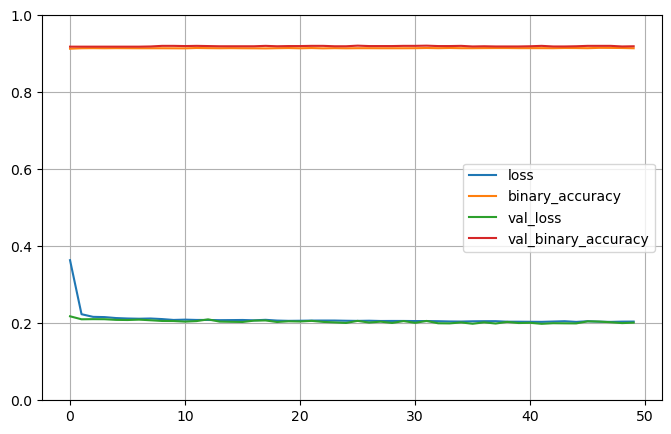

In [13]:
pd.DataFrame(history.history).plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0, 1)
plt.show()

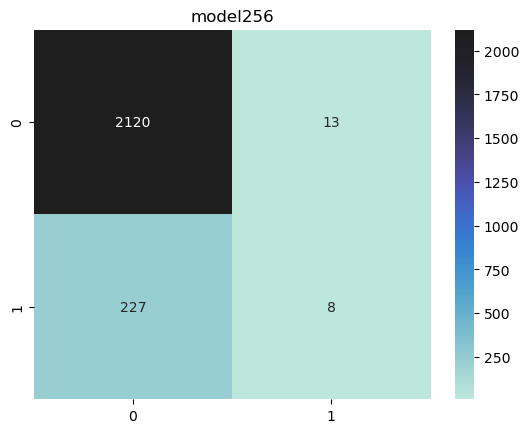

In [14]:
filtered_data, TP, FP, TN, FN = test_model(model, test_ds)

array = [[TN, FP],
        [FN, TP]]

df_cm = pd.DataFrame(array, range(2), range(2))
sn.heatmap(df_cm, annot=True, center=TN, fmt='g')
plt.title('model256')

plt.show()

In [15]:
model.save('./trained_models/model512')

INFO:tensorflow:Assets written to: ./trained_models/model512\assets


INFO:tensorflow:Assets written to: ./trained_models/model512\assets


In [8]:
model256 = keras.models.load_model('./trained_models/model256_1.h5')
model256.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 256, 256, 16)      448       
                                                                 
 conv2d_1 (Conv2D)           (None, 256, 256, 3)       195       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 128, 128, 3)      0         
 )                                                               
                                                                 
 sequential_23 (Sequential)  (None, 1)                 264708    
                                                                 
Total params: 265,351
Trainable params: 643
Non-trainable params: 264,708
_________________________________________________________________


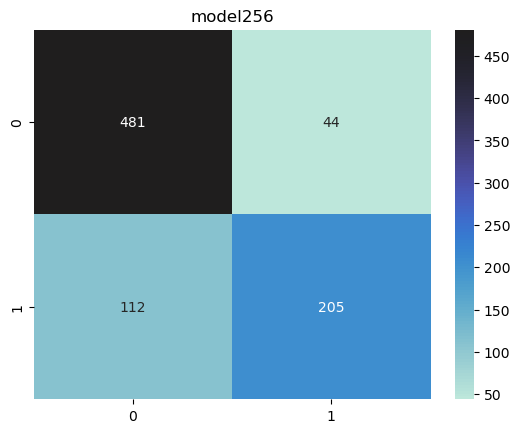

In [9]:
filtered_data, TP, FP, TN, FN = test_model(model256, test_ds)

array = [[TN, FP],
        [FN, TP]]

df_cm = pd.DataFrame(array, range(2), range(2))
sn.heatmap(df_cm, annot=True, center=TN, fmt='g')
plt.title('model256')

plt.show()

# Trying out k-mean clustering

Na het uitwerken is dit de best manier. Unsupervised learning via k-mean clustering.

In [1]:
import numpy as np
import skimage.io
import skimage.color
import skimage.filters
import skimage.transform
import matplotlib.pyplot as plt
import os
import shutil
import pandas as pd
import tensorflow as tf
from keras import layers
import keras
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import time
from joblib import Parallel, delayed
import joblib
import cv2

print(tf.__version__)
print(tf.config.list_physical_devices())

2.10.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Prepare the data

In [3]:
startTime = time.time()
# def append_image(filename):
#     img = skimage.io.imread(f'{path}{filename}')
#     img = skimage.transform.resize(img, (64,64))
#     data.append(img)
#     aantal = len(os.listdir(path))
#     teller = 0
#     for filename in os.listdir(path):
#         img = skimage.io.imread(f'{path}{filename}')
#         img = skimage.transform.resize(img, (64,64))
#         data.append(img)
#     teller += 1
#     print(f'{teller}/{aantal}', end='\r')

# path = './data/images_512/'
# data = []
# Parallel(n_jobs=-1, prefer='threads', require='sharedmem', verbose=1)(
#     delayed(append_image)(filename) for filename in os.listdir(path)
# )
# data = np.asarray(data)
# print(data.shape[0])
# data = data.reshape((data.shape[0], -1))

smallset = tf.keras.utils.image_dataset_from_directory(
    directory='./data/old_images_full/',
    labels=None,
    batch_size=10,
    image_size=(64,64),
    # validation_split=0.2,
    # subset='both',
    # seed=42,
    shuffle=False,
)
def process(image):
    # image = tf.cast(image/255. ,tf.float32)
    image = image/255
    return image
smallset = smallset.map(process)
endTime = time.time()-startTime
print(f'Time elapsed: {round(endTime//60,0)}m {round(endTime%60,2)}s')

Found 80 files belonging to 1 classes.
Time elapsed: 0.0m 0.09s


In [4]:
startTime = time.time()
data = list(tf.data.Dataset.as_numpy_iterator(smallset.unbatch()))
data = np.array(data)
print(data.shape)
data = data.reshape((data.shape[0], -1))
print(data.shape)
endTime = time.time()-startTime
print(f'Time elapsed: {endTime//60}m {round(endTime%60,2)}s')

(80, 64, 64, 3)
(80, 12288)
Time elapsed: 0.0m 3.27s


### Train the model

In [5]:
startTime = time.time()
kmeans = KMeans(n_clusters=2, verbose=1)
kmeans.fit(X=data)
endTime = time.time()-startTime
print(f'Time elapsed: {endTime//60}m {round(endTime%60,2)}s')

Initialization complete
Iteration 0, inertia 32106.94140625
Iteration 1, inertia 17084.177734375
Iteration 2, inertia 17038.083984375
Converged at iteration 2: strict convergence.
Initialization complete
Iteration 0, inertia 34989.49609375
Iteration 1, inertia 18588.876953125
Iteration 2, inertia 18560.3203125
Converged at iteration 2: strict convergence.
Initialization complete
Iteration 0, inertia 32053.5
Iteration 1, inertia 17170.609375
Iteration 2, inertia 17092.9453125
Iteration 3, inertia 17041.859375
Iteration 4, inertia 17030.240234375
Converged at iteration 4: strict convergence.
Initialization complete
Iteration 0, inertia 32062.3359375
Iteration 1, inertia 17368.755859375
Iteration 2, inertia 17121.1015625
Iteration 3, inertia 17076.310546875
Iteration 4, inertia 17039.90234375
Iteration 5, inertia 17028.193359375
Converged at iteration 5: strict convergence.
Initialization complete
Iteration 0, inertia 32773.484375
Iteration 1, inertia 18502.25
Iteration 2, inertia 18348.3

### Filter the data in different folders

In [17]:
img = skimage.io.imread(f'./data/images_512/DSC00174_1.JPG')
# img = skimage.transform.resize(img, (64,64))
img = img/255
img = cv2.resize(img, (64,64))
img = img.reshape((1, -1))
img = np.array(img, dtype=np.float32)

print(img[0])
print(data[0])

[0.5029412  0.30784315 0.23039216 ... 0.76960784 0.5539216  0.43235293]
[0.5009804  0.30686274 0.22647059 ... 0.76666665 0.5509804  0.42941177]


In [10]:
def sort_prediction(filename, path, parentdir):
    img = skimage.io.imread(f'{path}/{filename}')
    img = img/255
    img = cv2.resize(img, (64,64))
    img = img.reshape((1, -1))
    img = np.array(img, dtype=np.float32)

    sortdir = kmeans.predict(img)[0]
    shutil.copy(f"{path}/{filename}", f"{parentdir}/{sortdir}/{filename}")
    
    # teller += 1
    # print(f'{teller}/{aantal}', end='\r')

path = './data/test/'
parentdir = './data/images_512_kmeans/'

# Remove the directories so we can stat anew
if os.path.isdir(parentdir):
    shutil.rmtree(parentdir)
os.makedirs(parentdir)
os.makedirs(f"{parentdir}/1")
os.makedirs(f"{parentdir}/0")

Parallel(n_jobs=-1, verbose=2, prefer='threads')(
    delayed(sort_prediction)(filename, path, parentdir) for filename in os.listdir(path)
)

# for filename in os.listdir(path):
#     sort_prediction(filename, path)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:    1.3s
[Parallel(n_jobs=-1)]: Done 122 tasks      | elapsed:    8.2s
[Parallel(n_jobs=-1)]: Done 325 tasks      | elapsed:   21.8s
[Parallel(n_jobs=-1)]: Done 608 tasks      | elapsed:   40.7s
[Parallel(n_jobs=-1)]: Done 973 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done 1418 tasks      | elapsed:  1.6min
[Parallel(n_jobs=-1)]: Done 1945 tasks      | elapsed:  2.3min
[Parallel(n_jobs=-1)]: Done 2000 out of 2000 | elapsed:  2.3min finished


[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,

In [19]:
startTime = time.time()
def filter(filename, sortdir, path, parentdir):
    # img = skimage.io.imread(f'{path}/{filename}')
    # img = img/255
    # img = cv2.resize(img, (64,64))
    # img = img.reshape((1, -1))
    # img = np.array(img, dtype=np.float32)

    # sortdir = kmeans.predict(img)[0]
    shutil.copy(f"{path}/{filename}", f"{parentdir}/{sortdir}/{filename}")
    
    # teller += 1
    # print(f'{teller}/{aantal}', end='\r')

path = './data/images_512/'
parentdir = './data/images_512_kmeans/'

# Remove the directories so we can stat anew
if os.path.isdir(parentdir):
    shutil.rmtree(parentdir)
os.makedirs(parentdir)
os.makedirs(f"{parentdir}/1")
os.makedirs(f"{parentdir}/0")

dataset = tf.keras.utils.image_dataset_from_directory(
    directory=path,
    labels=None,
    batch_size=10,
    image_size=(64,64),
    # validation_split=0.2,
    # subset='both',
    # seed=42,
    shuffle=False,
)
def process(image):
    # image = tf.cast(image/255. ,tf.float32)
    image = image/255
    return image

print("Start preprocessing")
dataset = dataset.map(process)

dataset = list(tf.data.Dataset.as_numpy_iterator(dataset.unbatch()))
dataset = np.array(dataset)
dataset = dataset.reshape((dataset.shape[0], -1))
prediction = kmeans.predict(dataset)

img_dir = os.listdir(path)

print("Start filtering")
Parallel(n_jobs=-1, verbose=2, prefer='threads')(
    delayed(filter)(filename, pred, path, parentdir) for filename, pred in zip(img_dir, prediction)
)

endTime = time.time()-startTime
print(f'Time elapsed: {endTime//60}m {round(endTime%60,2)}s')

Found 117450 files belonging to 1 classes.
Start preprocessing
Start filtering


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 122 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 325 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 608 tasks      | elapsed:    0.3s
[Parallel(n_jobs=-1)]: Done 973 tasks      | elapsed:    0.5s
[Parallel(n_jobs=-1)]: Done 1418 tasks      | elapsed:    0.8s
[Parallel(n_jobs=-1)]: Done 1945 tasks      | elapsed:    1.1s
[Parallel(n_jobs=-1)]: Done 2552 tasks      | elapsed:    1.6s
[Parallel(n_jobs=-1)]: Done 3241 tasks      | elapsed:    2.0s
[Parallel(n_jobs=-1)]: Done 4010 tasks      | elapsed:    2.4s
[Parallel(n_jobs=-1)]: Done 4861 tasks      | elapsed:    3.0s
[Parallel(n_jobs=-1)]: Done 5792 tasks      | elapsed:    3.7s
[Parallel(n_jobs=-1)]: Done 6805 tasks      | elapsed:    4.4s
[Parallel(n_jobs=-1)]: Done 7898 tasks      | elapsed:    5.1s
[Parallel(n_jobs=-1)]: Done 9073 tasks   

Time elapsed: 6.0m 42.94s


[Parallel(n_jobs=-1)]: Done 117450 out of 117450 | elapsed:  1.5min finished


### See how many we missed

In [15]:
images = os.listdir('./data/images_512_kmeans/0/')
labels = os.listdir('./data/label_512/')
if os.path.isdir("./data/images_512_kmeans/notFound/"):
    shutil.rmtree("./data/images_512_kmeans/notFound/")
os.makedirs("./data/images_512_kmeans/notFound/")
notFound = []
for image in images:
    imagename = image.split('.')[0]
    if f"{imagename}.txt" in labels:
        notFound.append(imagename)
        shutil.copy(f"./data/images_512_kmeans/0/{imagename}.JPG", 
                    f"./data/images_512_kmeans/notFound/{imagename}.JPG")
        # print(labelname)
print(f'{len(notFound)}/{len(images)}')
print(f'{1 - len(notFound)/len(images)}')

64/1632
0.9607843137254902


### Save the model

In [17]:
joblib.dump(kmeans, "./trained_models/kmeans") 

['./trained_models/kmeans']

In [2]:
loaded_kmeans = joblib.load('./trained_models/kmeans')

In [30]:
kmeans = joblib.load('./trained_models/kmeans')

In [23]:
kmeans = joblib.load('./trained_models_testing/kmeans')